# Module 1 — Corporate Finance: run the whole module

**How to use:**
- **Run all** to run the full module in order, or run a single cell to run one step.
- Each cell runs one task notebook in full and shows all its tables and charts here.
- Every task notebook also runs on its own: open it from `notebooks/` and run all.

**Order matters:** Task 3 reads the P(Success) file that Task 2 saves (`outputs/task2/FINAL_M1_T2_success_probability.csv`). So run Task 2 before Task 3, or rely on the file Task 2 saved last time.

| Step | Notebook | Status |
| --- | --- | --- |
| 0. Data check | `helpers/m01_data.py` | Built |
| 1. Task 1 — Exploratory analysis | `notebooks/m01_task1_eda.ipynb` | Built |
| 2. Task 2 — Predict initiative success | `notebooks/m01_task2_model.ipynb` | Built |
| 3. Task 3 — Financial decision | `notebooks/m01_task3_decision.ipynb` | Built |
| Final. Output workbook | `helpers/m01_final_output.py` → `outputs/FINAL_M1_module_output.xlsx` | Built |

Findings with charts: `reports/`. Status: `docs/progress.md`.


## Setup
Moves into the module folder so the paths below work, both locally and in Google Colab.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.

In [1]:
import os
import sys
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]
os.chdir(PROJECT_ROOT / "module_01_corporate_finance")                  # the paths below start from the module folder
print("Working folder:", Path.cwd().name)

Working folder: module_01_corporate_finance


## 0. Data check
Is `strategic_initiatives.csv` complete and clean? Prints rows, missing values, duplicates, success rate and totals.

In [2]:
%run helpers/m01_data.py

rows: 180
missing_values: 0
duplicate_ids: 0
negative_money_values: 0
success_rate: 0.767
total_investment_crore: 283.4
business_units: {'Payments': 36, 'Corporate Banking': 35, 'Wealth': 35, 'Digital Banking': 34, 'Risk Analytics': 25, 'SME Lending': 15}
risk_ratings: {'Medium': 72, 'Low': 64, 'High': 44}


## 1. Task 1 — Exploratory analysis
Runs `notebooks/m01_task1_eda.ipynb`:
- data quality checks;
- the six items the brief lists: investment, ROI, risk categories, business units, growth vs ROI, investment vs success.

Saves its tables and charts to `outputs/task1/`.

Project folder found
Outputs go to:  module_01_corporate_finance/outputs/task1
180 initiatives, 21 columns (given + derived)


,Check,Result
0,Rows,180
1,Missing values (all columns),0
2,Duplicate Initiative_ID,0
3,Negative money values,0
4,Expected_ROI ≤ 0,0
5,Expected_ROI exactly at the 2.00% floor,11
6,Business_Growth < 0,1
7,Revenue falls Year 1 → Year 3,0
8,Operating_Cost > Year 1 revenue,18
9,Business_Unit labels,"Corporate Banking, Digital Banking, Payments, ..."


,count,total_crore,mean,min,25%,50%,75%,max
All initiatives,180.0,283.4,157.5,31.5,89.3,155.3,226.9,296.5
Corporate Banking,35.0,62.3,178.1,42.2,104.2,190.0,248.4,296.5
Digital Banking,34.0,47.1,138.6,36.9,73.1,127.9,187.9,292.4
Payments,36.0,53.3,148.1,39.3,77.2,117.5,220.6,281.0
Risk Analytics,25.0,39.8,159.1,34.5,90.0,167.3,219.8,289.9
SME Lending,15.0,22.3,148.5,31.9,78.3,112.2,227.4,296.1
Wealth,35.0,58.6,167.5,31.5,116.4,163.7,226.7,291.9


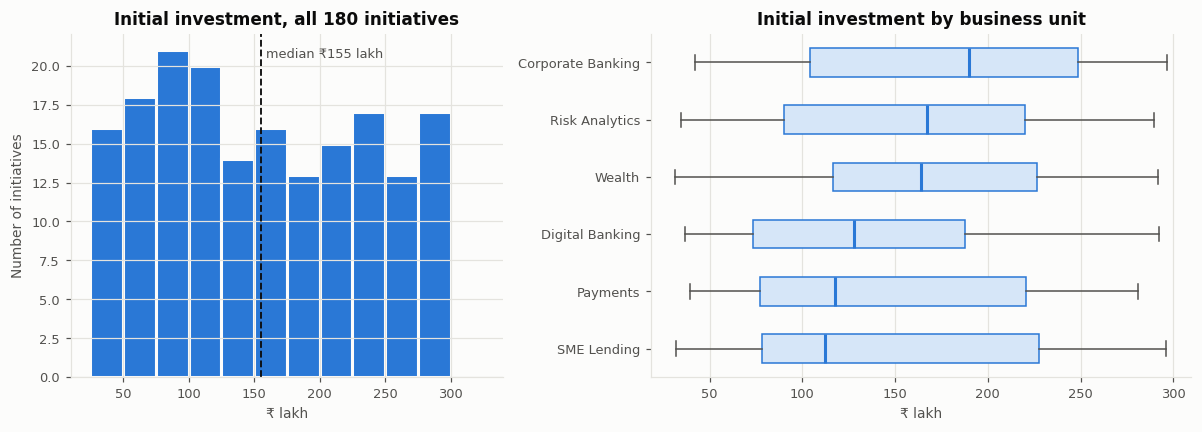

,Group,n,Expected_ROI_median,Expected_ROI_p25,Expected_ROI_p75,Cash_Return_median,Interest_Rate_median,Share_ROI_above_Interest
0,All initiatives,180,10.50,7.31,14.23,20.67,6.99,0.75
1,Unit: Corporate Banking,35,9.51,7.92,14.02,21.70,7.14,0.74
2,Unit: Digital Banking,34,12.60,9.20,15.39,20.99,6.93,0.82
3,Unit: Payments,36,10.24,7.60,14.03,21.14,6.98,0.81
4,Unit: Risk Analytics,25,10.41,5.21,12.67,20.37,7.08,0.64
5,Unit: SME Lending,15,11.38,5.78,13.14,15.71,7.04,0.67
6,Unit: Wealth,35,9.70,7.08,14.04,19.86,6.85,0.74
7,Risk: Low,64,11.99,8.11,14.59,21.01,6.87,0.80
8,Risk: Medium,72,11.35,8.00,14.47,20.95,6.98,0.78
9,Risk: High,44,8.32,5.62,11.52,19.90,7.26,0.64


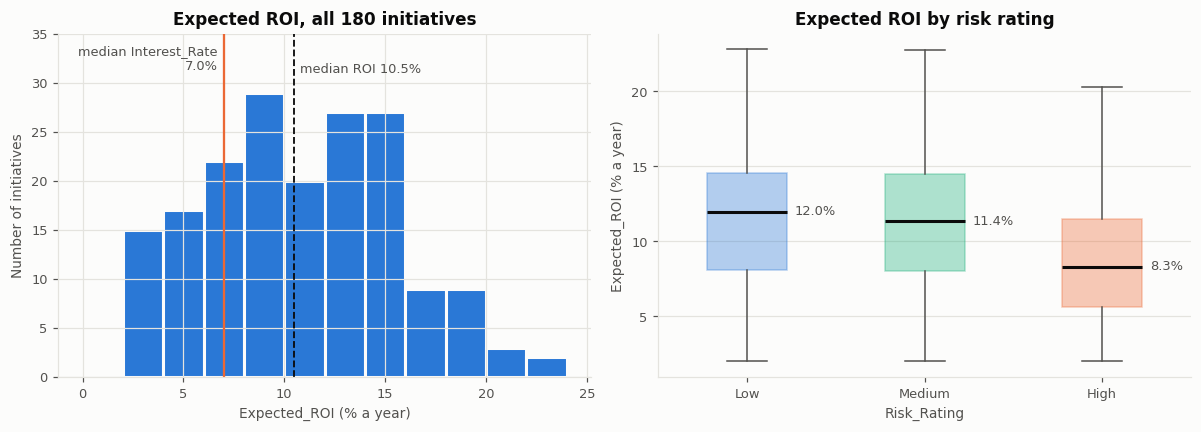

Extra results: {'chi_square_p_value': 0.0139}


,Risk_Rating,n,share,success_rate,success_ci_low,success_ci_high,Expected_ROI_median,Investment_median,Total_investment_crore,NPV_3yr_median
0,Low,64,0.356,0.891,0.791,0.946,11.99,143.715,98.603,-55.548
1,Medium,72,0.400,0.694,0.580,0.789,11.35,166.080,119.423,-65.521
2,High,44,0.244,0.705,0.558,0.818,8.32,145.380,65.422,-50.351


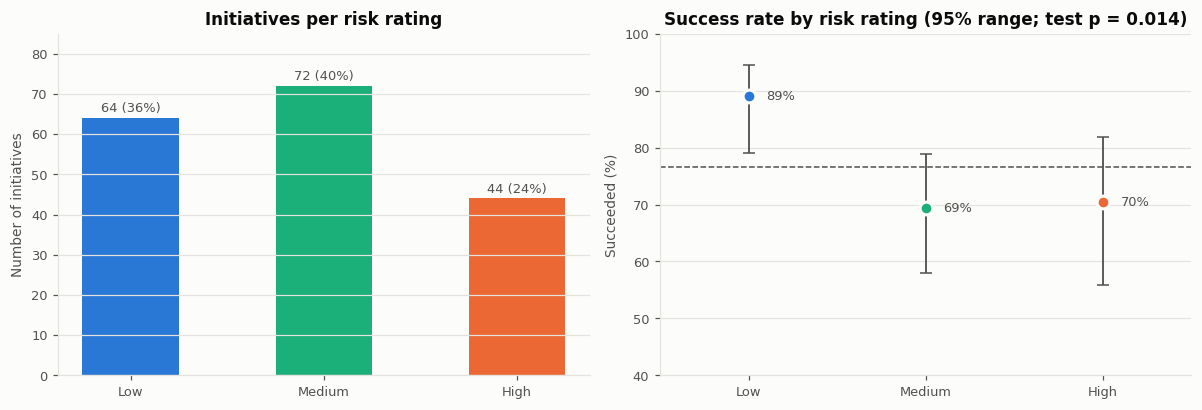

Extra results: {'chi_square_p_value': 0.3586}


,Business_Unit,n,Total_investment_crore,success_rate,success_ci_low,success_ci_high,Expected_ROI_median,Cash_Return_median,Business_Growth_median,NPV_3yr_median,NPV_3yr_positive,High_risk_share
4,SME Lending,15,22.279,0.867,0.621,0.963,11.380,15.706,7.380,-54.185,1,0.133
3,Risk Analytics,25,39.772,0.840,0.653,0.936,10.410,20.370,8.030,-77.117,0,0.240
1,Digital Banking,34,47.138,0.794,0.632,0.897,12.595,20.989,9.360,-56.300,1,0.265
2,Payments,36,53.325,0.778,0.619,0.883,10.245,21.137,8.595,-62.348,0,0.306
5,Wealth,35,58.613,0.771,0.610,0.879,9.700,19.858,7.820,-47.092,4,0.286
0,Corporate Banking,35,62.321,0.629,0.463,0.768,9.510,21.701,8.350,-69.941,2,0.171


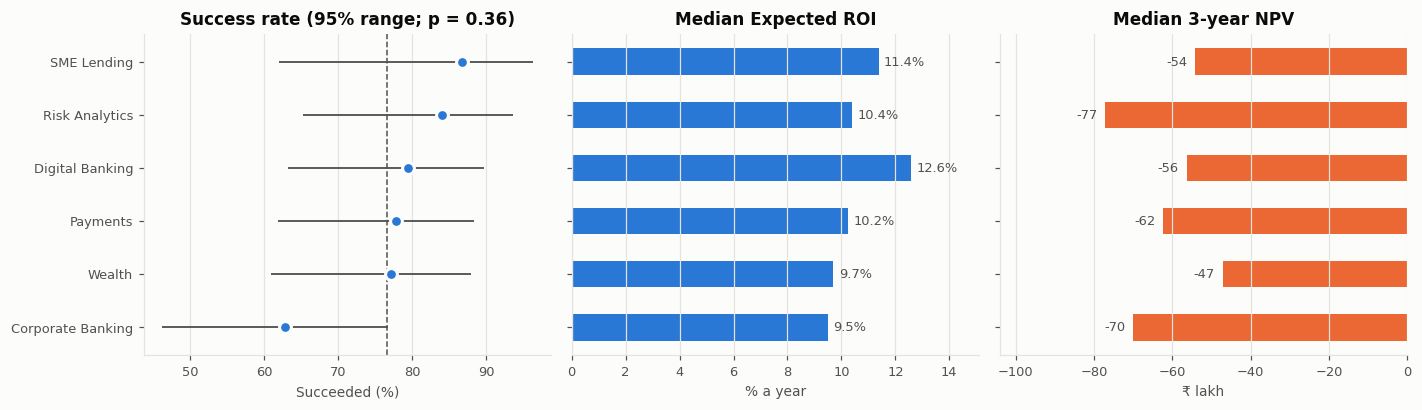

,Growth_measure,ROI_measure,Pearson_r,Pearson_p,Spearman_rho,Spearman_p,Slope_ROI_per_1pt_growth
0,Business_Growth,Expected_ROI,0.5606,0.0000,0.5558,0.0000,0.9122
1,Business_Growth,Cash_Return_Pct,0.3278,0.0000,0.3262,0.0000,1.2362
2,GDP_Growth,Expected_ROI,0.1179,0.1150,0.1225,0.1014,0.3335
3,GDP_Growth,Cash_Return_Pct,0.0624,0.4051,0.0354,0.6371,0.4092
4,Revenue_Growth_Y1_Y3,Expected_ROI,0.0345,0.6458,0.0508,0.4986,0.0123
5,Revenue_Growth_Y1_Y3,Cash_Return_Pct,0.2209,0.0029,0.1936,0.0092,0.1824


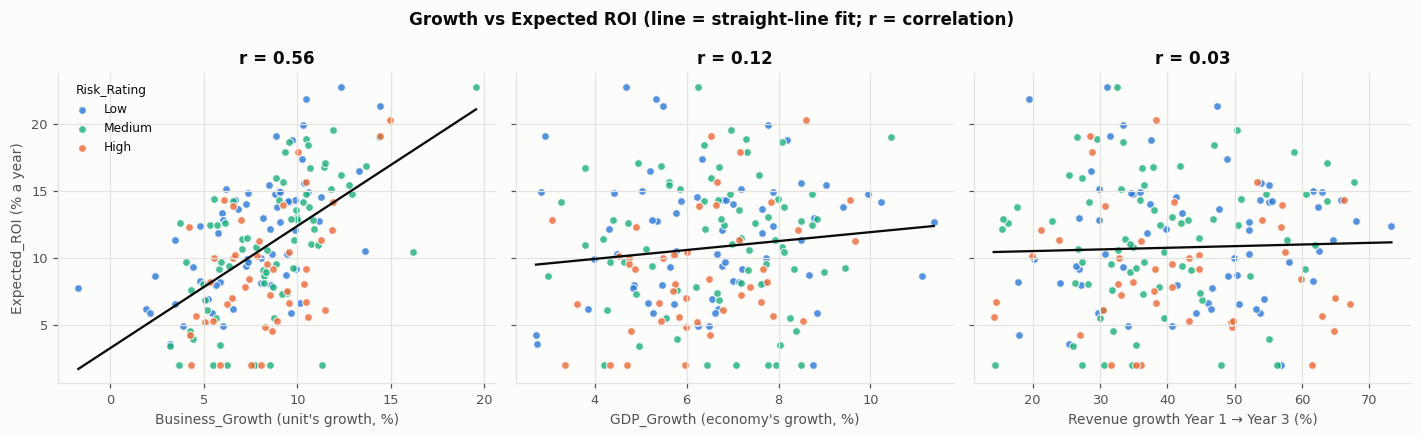

Extra results: {'median_succeeded': 151.0, 'median_failed': 162.4, 'mann_whitney_p': 0.896, 'point_biserial_r': 0.01}


,Investment_band,n,range_lakh,success_rate,success_ci_low,success_ci_high,NPV_3yr_median
0,Small,60,31–108,0.767,0.646,0.856,-24.747
1,Mid-size,60,109–201,0.783,0.664,0.869,-65.837
2,Large,60,201–296,0.750,0.628,0.842,-123.552


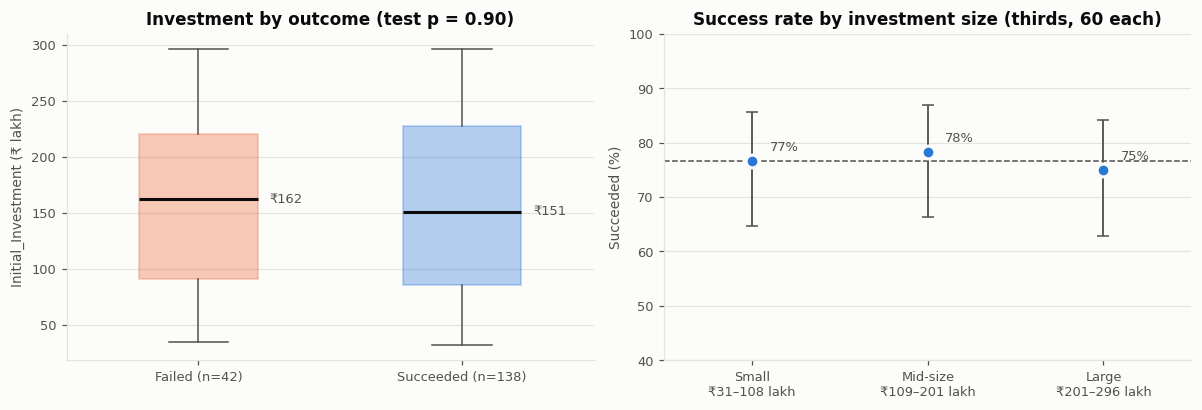

,Historical_Success,Expected_ROI,NPV_3yr
Initial_Investment,0.01,0.07,-0.60
Revenue_Year1,0.01,0.32,-0.33
Revenue_Year3,0.03,0.32,-0.31
Operating_Cost,0.03,0.07,-0.80
Expected_ROI,0.12,1.00,0.35
Business_Growth,0.09,0.56,0.23
GDP_Growth,-0.03,0.12,0.03
Interest_Rate,-0.02,-0.19,-0.08
Competition_Index,-0.07,0.01,-0.03
Revenue_Growth_Y1_Y3,0.07,0.03,0.15


{
  "rows": 180,
  "success_rate": 0.767,
  "total_investment_crore": 283.4,
  "risk_chi_square_p": 0.0139,
  "unit_chi_square_p": 0.3586,
  "investment_vs_success": {
    "median_succeeded": 151.0,
    "median_failed": 162.4,
    "mann_whitney_p": 0.896,
    "point_biserial_r": 0.01
  },
  "npv_3yr_positive": 8,
  "hurdle_pass": 135
}
Total capital ₹283.4 crore; failed capital ₹65.5 crore (23% of all capital)


,Initiatives,Capital (₹ crore),Share of capital,Success rate,Failed capital (₹ crore),Failed share of its capital,Share of all failed capital,Median Expected_ROI (%),Passes hurdle
Risk_Rating,,,,,,,,,
Low,64,98.603,0.348,0.891,9.190,0.093,0.14,11.99,0.797
Medium,72,119.423,0.421,0.694,35.348,0.296,0.54,11.35,0.778
High,44,65.422,0.231,0.705,20.978,0.321,0.32,8.32,0.636


,Initiatives,Capital (₹ crore),Share of capital,Success rate,Failed capital (₹ crore),Failed share of its capital,Share of all failed capital,Median Expected_ROI (%),Passes hurdle
Business_Unit,,,,,,,,,
Corporate Banking,35,62.321,0.220,0.629,23.096,0.371,0.353,9.510,0.743
Wealth,35,58.613,0.207,0.771,12.279,0.209,0.187,9.700,0.743
Payments,36,53.325,0.188,0.778,11.961,0.224,0.183,10.245,0.806
Digital Banking,34,47.138,0.166,0.794,7.815,0.166,0.119,12.595,0.824
SME Lending,15,22.279,0.079,0.867,5.249,0.236,0.080,11.380,0.667
Risk Analytics,25,39.772,0.140,0.840,5.116,0.129,0.078,10.410,0.640


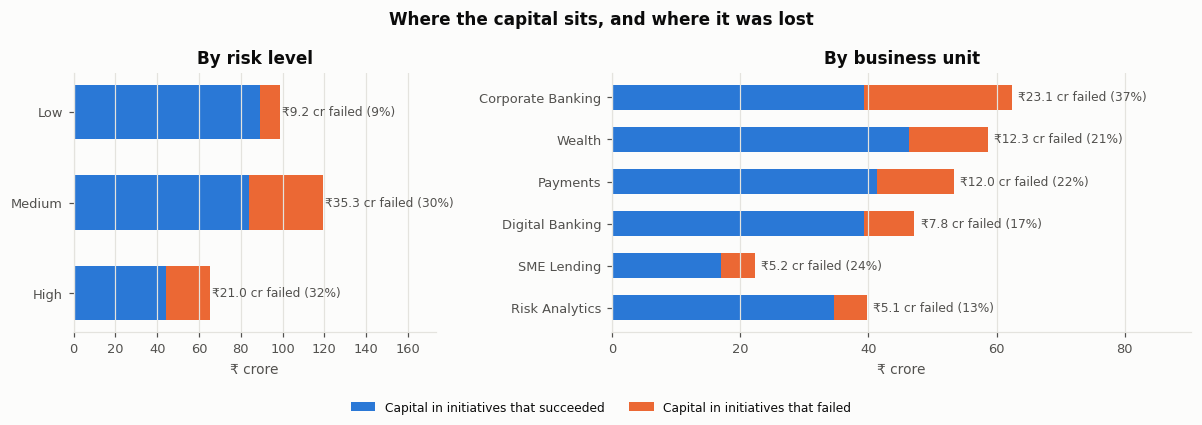

In [3]:
%run notebooks/m01_task1_eda.ipynb

## 2. Task 2 — Predict initiative success
Runs `notebooks/m01_task2_model.ipynb`. Takes about 19 minutes: 7 models × 25 cross-validation rounds, plus the balancing comparison and the shuffled-label check.
- compares 7 models;
- explains what drives success (odds ratios, lasso, SHAP);
- saves P(Success) per initiative to `outputs/task2/FINAL_M1_T2_success_probability.csv` for Task 3.

Project folder found
Outputs go to:  module_01_corporate_finance/outputs/task2
Initiatives: 180 | successes: 138 | failures: 42 | base rate: 0.767
Inputs: 10 given + 7 derived numbers + 9 one-hot columns = 26


,Derived column,Formula
0,CF1,Revenue_Year1 − Operating_Cost (₹ lakh)
1,CF2,Revenue_Year2 − Operating_Cost (₹ lakh)
2,CF3,Revenue_Year3 − Operating_Cost (₹ lakh)
3,NPV_3yr,−Initial_Investment + CF1/(1 + r) + CF2/(1 + r...
4,Revenue_Growth_Y1_Y3,(Revenue_Year3 ÷ Revenue_Year1 − 1) × 100 (%)
5,Cash_Return_Pct,"average(CF1, CF2, CF3) ÷ Initial_Investment × ..."
6,ROI_Spread,Expected_ROI − Interest_Rate (% points; above...


,Round,Train rows,Test rows,Failures in test,Success rate in train
0,1,144,36,8,0.764
1,2,144,36,8,0.764
2,3,144,36,8,0.764
3,4,144,36,9,0.771
4,5,144,36,9,0.771


Total rounds per model: 25
Models: Baseline, Lasso, Logistic regression, Decision tree, Random forest, XGBoost, LightGBM


Mean ± standard deviation over 25 rounds (Fail_ = failure class at the base-rate cut-off):


,ROC_AUC,Brier,Log_loss,Accuracy,Fail_precision,Fail_recall,Fail_F1,Mean_P
Model,,,,,,,,
Baseline,0.5 ± 0.0,0.179 ± 0.007,0.544 ± 0.017,0.767 ± 0.014,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.767 ± 0.003
Lasso,0.578 ± 0.08,0.18 ± 0.018,0.551 ± 0.069,0.52 ± 0.069,0.292 ± 0.05,0.736 ± 0.159,0.415 ± 0.069,0.748 ± 0.016
Logistic regression,0.562 ± 0.119,0.192 ± 0.023,0.594 ± 0.082,0.563 ± 0.086,0.279 ± 0.081,0.543 ± 0.174,0.366 ± 0.105,0.766 ± 0.025
Decision tree,0.521 ± 0.133,0.21 ± 0.034,1.029 ± 0.493,0.524 ± 0.088,0.238 ± 0.105,0.558 ± 0.331,0.325 ± 0.153,0.767 ± 0.03
Random forest,0.457 ± 0.102,0.189 ± 0.014,0.572 ± 0.039,0.474 ± 0.081,0.2 ± 0.076,0.431 ± 0.196,0.27 ± 0.105,0.761 ± 0.015
XGBoost,0.488 ± 0.089,0.212 ± 0.019,0.661 ± 0.073,0.566 ± 0.072,0.221 ± 0.08,0.339 ± 0.144,0.263 ± 0.095,0.785 ± 0.033
LightGBM,0.499 ± 0.09,0.212 ± 0.022,0.676 ± 0.085,0.583 ± 0.076,0.227 ± 0.071,0.33 ± 0.146,0.263 ± 0.093,0.794 ± 0.038


,ROC-AUC on training rows,ROC-AUC on test rows,Brier on training rows,Brier on test rows,ROC-AUC gap (train − test),Brier gap (test − train)
Model,,,,,,
Baseline,0.500,0.500,0.179,0.179,0.000,0.000
Lasso,0.723,0.578,0.163,0.180,0.145,0.018
Logistic regression,0.759,0.562,0.151,0.192,0.197,0.041
Decision tree,0.787,0.521,0.141,0.210,0.266,0.069
Random forest,0.990,0.457,0.118,0.189,0.533,0.071
XGBoost,1.000,0.488,0.046,0.212,0.512,0.167
LightGBM,1.000,0.499,0.040,0.212,0.501,0.172


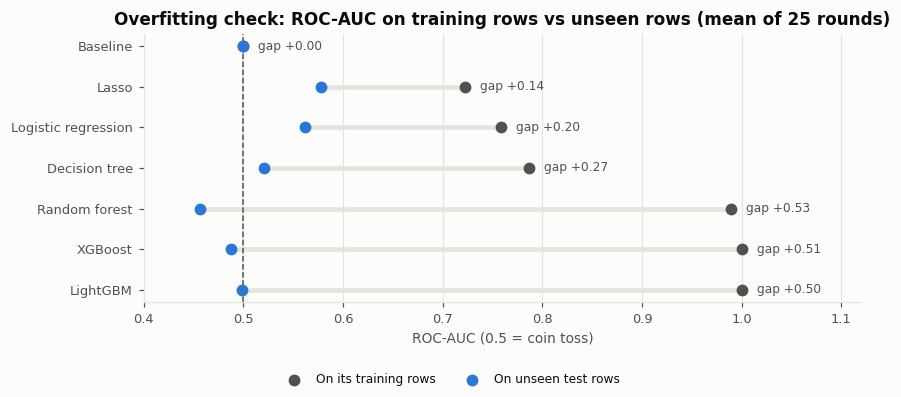

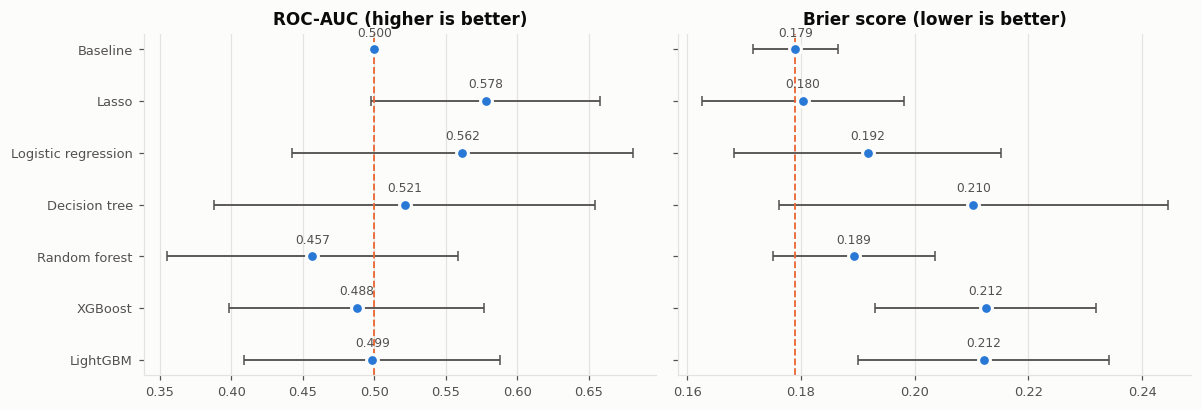

Real success rate: 0.767 | baseline Brier: 0.179


,"Mean P(Success), unweighted","Mean P(Success), balanced","Brier, unweighted","Brier, balanced","Failure recall, unweighted","Failure recall, balanced"
Model,,,,,,
Lasso,0.748,0.506,0.180,0.252,0.736,0.985
Logistic regression,0.766,0.551,0.192,0.256,0.543,0.807
Decision tree,0.767,0.580,0.210,0.263,0.558,0.797
Random forest,0.761,0.620,0.189,0.212,0.431,0.939
XGBoost,0.785,0.668,0.212,0.238,0.339,0.587
LightGBM,0.794,0.685,0.212,0.237,0.330,0.559


,Brier,ROC_AUC,Brier minus leader,95% range low,95% range high,AUC not clearly worse,Tied with leader
Model,,,,,,,
Lasso,0.1804,0.5779,0.0000,0.0000,0.0000,True,True
Logistic regression,0.1917,0.5617,0.0113,0.0050,0.0177,True,False
Decision tree,0.2103,0.5212,0.0299,0.0165,0.0434,False,False
Random forest,0.1893,0.4568,0.0089,0.0041,0.0137,False,False
XGBoost,0.2125,0.4876,0.0321,0.0245,0.0397,False,False
LightGBM,0.2121,0.4986,0.0318,0.0225,0.0410,False,False


Lowest Brier: Lasso  →  chosen (simplest model tied with it, AUC not clearly worse): Lasso


Benchmark minus Lasso, Brier: -0.0047 (95% range -0.0103 to +0.0010; includes 0: a tie)


,Brier (lower better),ROC-AUC,ROC-AUC std (stability),Failure recall,Average P(Success),Bias vs real 0.767,Effect on Expected NPV,Inputs used,Board can read it?
Baseline,0.179,0.500,0.000,0.000,0.767,-0.000,Neutral,0.0,Trivial: one number for everyone
Lasso,0.180,0.578,0.080,0.736,0.748,-0.019,Slightly understates Expected NPV (cautious),7.4,"Yes: a few weights, read as odds ratios"
Logistic regression,0.192,0.562,0.119,0.543,0.766,-0.001,Neutral,26.0,Partly: 26 weights to read
Decision tree,0.210,0.521,0.133,0.558,0.767,0.000,Neutral,26.0,Yes: a few yes/no questions
Random forest,0.189,0.457,0.102,0.431,0.761,-0.005,Neutral,26.0,"No: 300 trees, needs SHAP"
XGBoost,0.212,0.488,0.089,0.339,0.785,0.018,Overstates Expected NPV (risk of over-funding),26.0,"No: 200 trees, needs SHAP"
LightGBM,0.212,0.499,0.090,0.330,0.794,0.028,Overstates Expected NPV (risk of over-funding),26.0,"No: 200 trees, needs SHAP"
Risk rating only (benchmark),0.176,0.577,0.089,0.807,0.767,0.000,Neutral,1.0,Yes: one lookup by risk level


Baseline                       Not eligible: same P(Success) for every initiative, so it cannot rank or flag any
Lasso                          Chosen: best Brier among real models (or tied and simplest), ROC-AUC not worse, readable, few inputs
Logistic regression            Rejected: Brier clearly worse (+0.011; 95% range 0.005 to 0.018 does not include 0)
Decision tree                  Rejected: Brier clearly worse (+0.030; 95% range 0.017 to 0.043 does not include 0); ROC-AUC more than 0.05 below the best
Random forest                  Rejected: Brier clearly worse (+0.009; 95% range 0.004 to 0.014 does not include 0); ROC-AUC more than 0.05 below the best; ranks worse than a coin toss; a black box for the Board
XGBoost                        Rejected: Brier clearly worse (+0.032; 95% range 0.025 to 0.040 does not include 0); ROC-AUC more than 0.05 below the best; ranks worse than a coin toss; over-optimistic P(Success); a black box for the Board
LightGBM                       Rejec

,Initiatives,Failures,Lasso ROC-AUC within the level
Risk level,,,
Low,64,7,0.231
Medium,72,22,0.536
High,44,13,0.278


Total capital ₹283.4 crore; failed capital ₹65.5 crore (23% of all capital, in 42 failed initiatives)


,Flagged initiatives,Capital sent to review (₹ crore),Share of all capital reviewed,Failed capital caught (₹ crore),Share of failed capital caught,Failure rate among flagged,Failure rate among not flagged,Capital lift (caught ÷ reviewed),Flag points the right way?
Baseline,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,n/a
Lasso,106.0,168.439,0.594,49.390,0.754,0.302,0.135,1.269,Yes
Logistic regression,87.0,140.035,0.494,38.244,0.584,0.276,0.194,1.182,Yes
Decision tree,91.0,144.572,0.510,35.979,0.549,0.264,0.202,1.077,Yes
Random forest,98.0,155.989,0.550,33.218,0.507,0.204,0.268,0.921,No
XGBoost,71.0,104.510,0.369,25.115,0.383,0.211,0.248,1.040,No
LightGBM,67.0,101.568,0.358,27.028,0.413,0.224,0.239,1.151,No
Risk rating only (benchmark),116.0,184.844,0.652,56.327,0.860,0.302,0.109,1.318,Yes


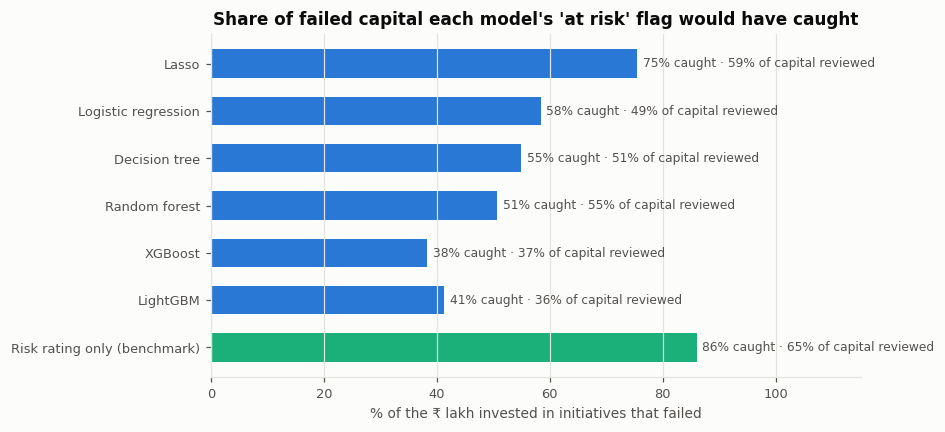

,Real ROC-AUC (5-fold),Shuffled 95th percentile,p-value
Lasso,0.583,0.626,0.168
Logistic regression,0.576,0.621,0.178


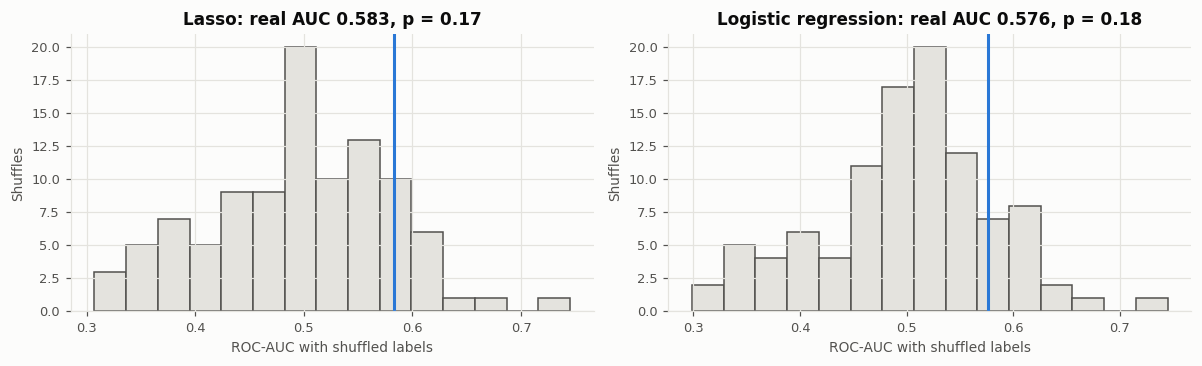

,Weight b,Odds ratio e^b
Business_Unit = Corporate Banking,-0.663,0.515
Risk_Rating = Medium,-0.406,0.666
Risk_Rating = High,-0.339,0.712
NPV_3yr,-0.245,0.783
Revenue_Year2,-0.198,0.820
Cash_Return_Pct,-0.190,0.827
CF2,-0.179,0.836
GDP_Growth,-0.153,0.858
Competition_Index,-0.136,0.873
Operating_Cost,-0.128,0.880


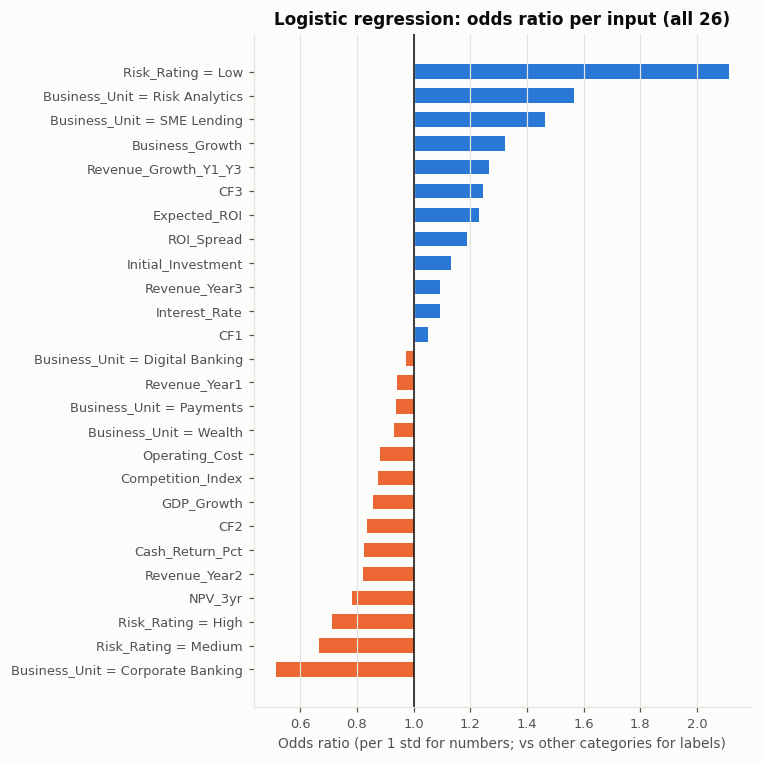

Lasso kept on average 7.4 of 26 inputs per round; inputs kept on the full fit: 9


,Kept in share of 25 rounds,Full-fit weight,Full-fit odds ratio
Risk_Rating = Low,1.00,0.878,2.407
Business_Growth,0.80,0.154,1.166
Business_Unit = Corporate Banking,0.68,-0.245,0.783
Revenue_Growth_Y1_Y3,0.68,0.066,1.068
GDP_Growth,0.68,-0.024,0.976
Expected_ROI,0.60,0.099,1.104
Competition_Index,0.60,-0.041,0.960
Cash_Return_Pct,0.48,-0.033,0.967
NPV_3yr,0.40,-0.039,0.962
ROI_Spread,0.32,0.000,1.000


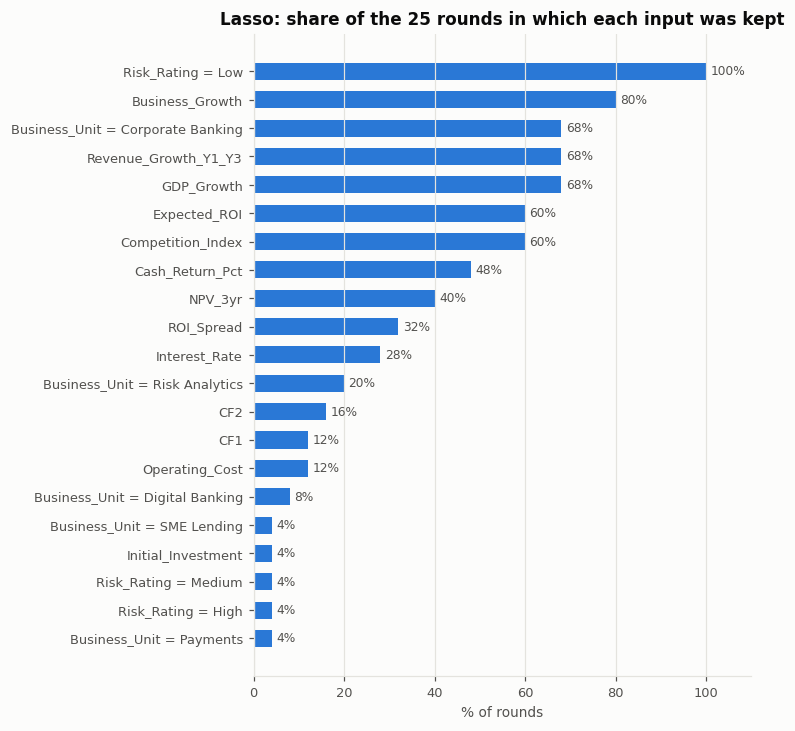

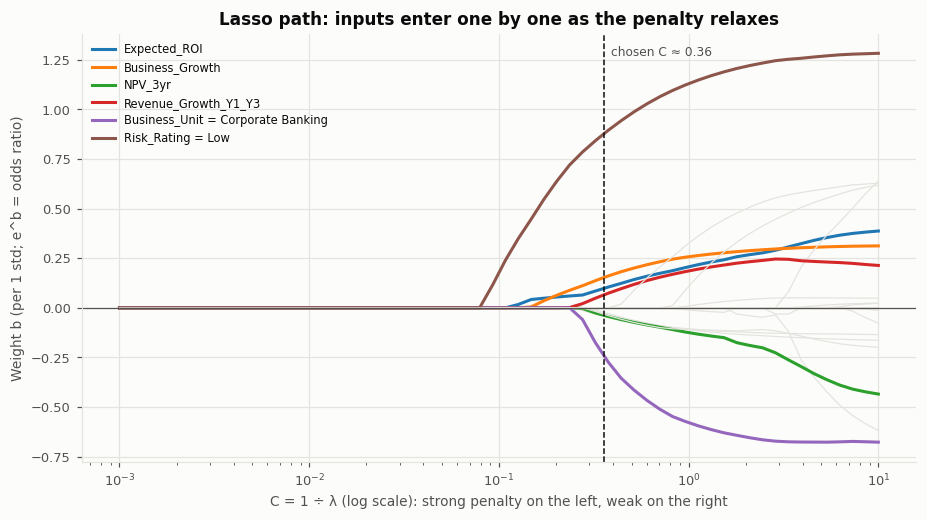

Order in which inputs enter the lasso path (first = strongest priority):


,Entry order,Enters at C,Kept in % of 25 rounds
Risk_Rating = Low,1,0.092,100.0
Expected_ROI,2,0.126,60.0
Business_Growth,3,0.148,80.0
Revenue_Growth_Y1_Y3,4,0.236,68.0
NPV_3yr,5,0.276,40.0
Business_Unit = Corporate Banking,6,0.276,68.0
Competition_Index,7,0.276,60.0
Cash_Return_Pct,8,0.322,48.0
GDP_Growth,9,0.322,68.0
Business_Unit = Risk Analytics,10,0.441,20.0


Penalty C chosen by the inner cross-validation in the 25 rounds (value: number of rounds):


,Rounds
Penalty_C,
0.3594,24
2.7826,1


Background dataset has 180 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=180 when initializing the masker.


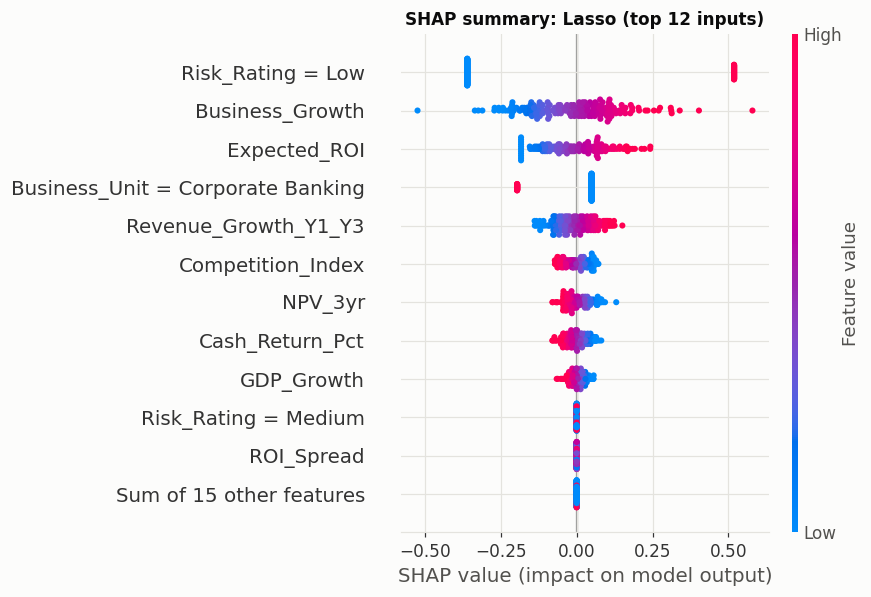

Lasso: top 8 inputs by mean |SHAP|


,Mean |SHAP|
Risk_Rating = Low,0.4164
Business_Growth,0.1210
Expected_ROI,0.0815
Business_Unit = Corporate Banking,0.0776
Revenue_Growth_Y1_Y3,0.0563
Competition_Index,0.0357
NPV_3yr,0.0314
Cash_Return_Pct,0.0262


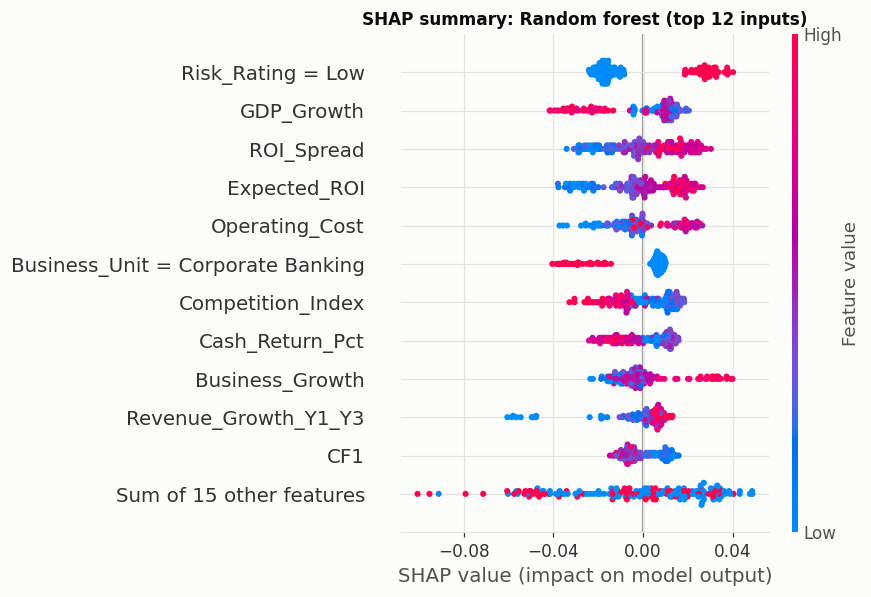

Random forest: top 8 inputs by mean |SHAP|


,Mean |SHAP|
Risk_Rating = Low,0.0210
GDP_Growth,0.0147
ROI_Spread,0.0140
Expected_ROI,0.0133
Operating_Cost,0.0113
Business_Unit = Corporate Banking,0.0112
Competition_Index,0.0110
Cash_Return_Pct,0.0102


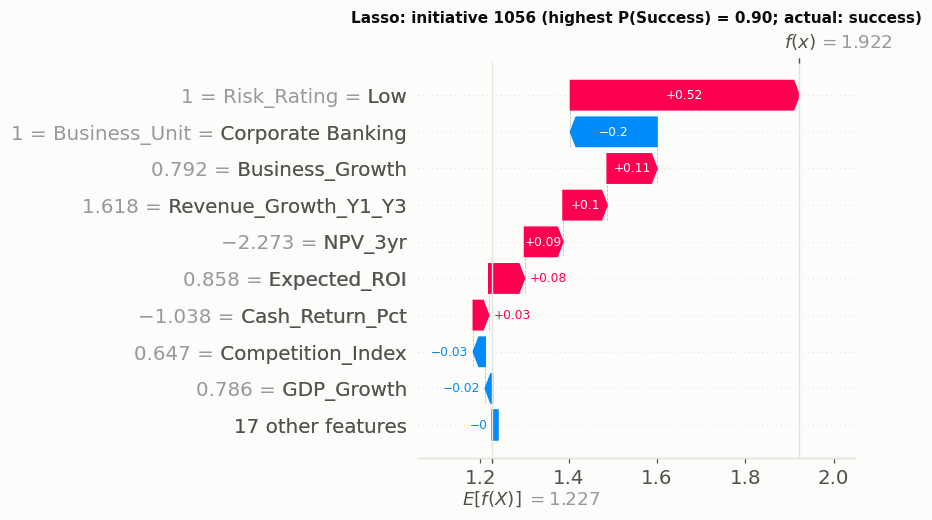

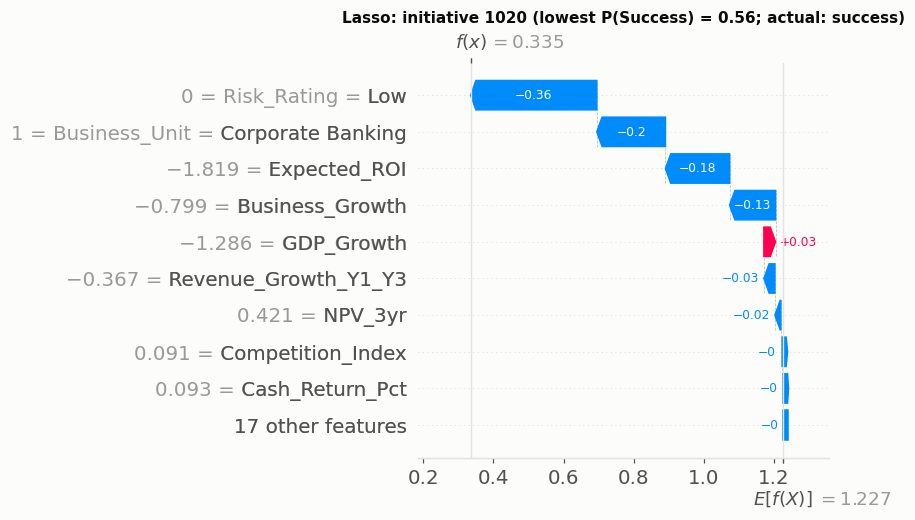

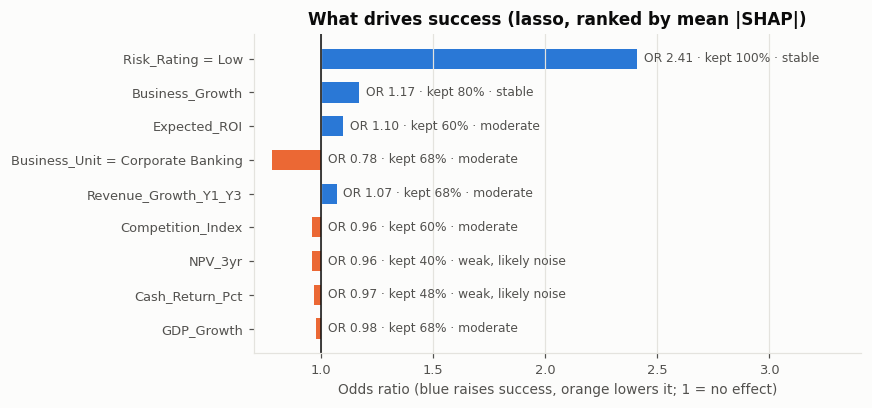

,Rank,Mean |SHAP| (lasso),Kept in % of rounds,Lasso odds ratio,Logistic odds ratio,Rank in Random forest SHAP,Direction,Logistic agrees?,Finance expects,Makes financial sense?,Signal,What it means for the bank
Risk_Rating = Low,1,0.416,100.0,2.41,2.11,1,Raises success,Yes,Raises,Yes,Stable,"Strongest lever: favour low-risk initiatives, or de-risk (pilot, phased funding) before approving"
Business_Growth,2,0.121,80.0,1.17,1.32,9,Raises success,Yes,Raises,Yes,Stable,Initiatives in fast-growing businesses succeed more often; weigh the unit's growth outlook
Expected_ROI,3,0.081,60.0,1.10,1.23,4,Raises success,Yes,Raises,Yes,Moderate,A higher planned return goes with success; ask for a credible ROI case
Business_Unit = Corporate Banking,4,0.078,68.0,0.78,0.52,6,Lowers success,Yes,No clear prior,n/a,Moderate,Succeeds less often than other units; extra review and tighter milestones
Revenue_Growth_Y1_Y3,5,0.056,68.0,1.07,1.27,10,Raises success,Yes,Raises,Yes,Moderate,Plans with faster revenue growth succeed slightly more often
Competition_Index,6,0.036,60.0,0.96,0.87,7,Lowers success,Yes,Lowers,Yes,Moderate,Crowded markets lower success slightly; check competitive position
NPV_3yr,7,0.031,40.0,0.96,0.78,14,Lowers success,Yes,Raises,No,"Weak, likely noise","Tiny, unstable effect: a high 3-year NPV on paper does not predict execution success"
Cash_Return_Pct,8,0.026,48.0,0.97,0.83,8,Lowers success,Yes,Raises,No,"Weak, likely noise","Tiny, unstable effect: strong paper cash returns do not predict success"
GDP_Growth,9,0.019,68.0,0.98,0.86,2,Lowers success,Yes,Raises,No,Moderate,Tiny effect against expectation; the unit's own growth matters more than the economy


,predicted,actual,low,high,n
g,,,,,
0,0.643,0.750,0.589,0.862,36
1,0.693,0.667,0.503,0.798,36
2,0.739,0.694,0.531,0.820,36
3,0.804,0.944,0.819,0.985,36
4,0.860,0.778,0.619,0.883,36


,Initiative_ID,P_Success,At_Risk
count,180.000,180.000,180.000
mean,1090.500,0.748,0.589
std,52.106,0.080,0.493
min,1001.000,0.557,0.000
25%,1045.750,0.684,0.000
50%,1090.500,0.742,1.000
75%,1135.250,0.822,1.000
max,1180.000,0.896,1.000


{
  "chosen_model": "Lasso",
  "lowest_brier_model": "Lasso",
  "best_tree_model": "Random forest",
  "baseline_brier": 0.179,
  "chosen_brier": 0.1804,
  "chosen_roc_auc": 0.578,
  "chosen_roc_auc_std": 0.08,
  "chosen_fail_recall": 0.736,
  "shuffled_label_p": {
    "Lasso": 0.168,
    "Logistic regression": 0.178
  },
  "p_success_range": [
    0.557,
    0.895
  ],
  "at_risk_count": 106,
  "at_risk_actual_failure_rate": 0.302,
  "not_at_risk_actual_failure_rate": 0.135,
  "lasso_inputs_kept_mean": 7.4,
  "benchmark_risk_only": {
    "roc_auc": 0.577,
    "brier": 0.1757,
    "brier_minus_chosen": [
      -0.0047,
      -0.0103,
      0.001
    ],
    "capital_lift": 1.318,
    "chosen_capital_lift": 1.269
  }
}


In [4]:
%run notebooks/m01_task2_model.ipynb

## 3. Task 3 — Financial decision
Runs `notebooks/m01_task3_decision.ipynb` (a few seconds). Reads `outputs/task2/FINAL_M1_T2_success_probability.csv`, so Task 2 must have run first.
- NPV, Expected NPV, break-even life and the hurdle check;
- Fund / Review / Reject for every initiative, with a reason, a priority and (for Fund) a funding condition;
- sensitivity: three sources of P(Success) and three break-even cut-offs;
- saves `outputs/task3/FINAL_M1_T3_initiative_decisions.csv`, the hand-off to Module 9.

Project folder found
Outputs go to:  module_01_corporate_finance/outputs/task3
180 initiatives; P(Success) from Task 2 model: Lasso
P(Success) range 0.557–0.895; base rate 0.767; flagged at risk: 106


,Initiative_ID,Business_Unit,Risk_Rating,Initial_Investment,P_Success,At_Risk
0,1001,SME Lending,Medium,131.13,0.6612,1
1,1002,SME Lending,Medium,286.69,0.7535,1
2,1003,Wealth,High,227.64,0.7346,1
3,1004,Digital Banking,Medium,191.64,0.6590,1
4,1005,Corporate Banking,Medium,72.13,0.6691,1


,Initiatives,Total NPV (₹ lakh),Total Expected NPV (₹ lakh)
All,180,-13353.3,-9881.6
NPV > 0,8,225.0,170.2
NPV ≤ 0,172,-13578.3,-10051.9


Initiatives with positive NPV (the only ones with positive Expected NPV):


,Initiative_ID,Business_Unit,Risk_Rating,Initial_Investment,NPV_3yr,P_Success,Expected_NPV
74,1075,Wealth,Low,220.85,55.57,0.87,48.19
30,1031,Wealth,Medium,194.04,53.69,0.75,40.05
2,1003,Wealth,High,227.64,37.74,0.73,27.72
178,1179,Digital Banking,High,282.92,28.61,0.71,20.31
153,1154,Wealth,Medium,162.15,31.34,0.64,20.20
61,1062,Corporate Banking,Low,103.26,9.86,0.79,7.81
73,1074,Corporate Banking,Medium,250.17,6.32,0.74,4.71
114,1115,SME Lending,High,201.02,1.91,0.65,1.25


Median break-even life: 5 years; never break even: 17; passes the hurdle: 135 of 180


Break_Even_Years,3,4,5,6,7,8,9,10,11+,never
Initiatives,8,32,44,26,18,8,7,4,16,17


,Label,Decision_Path,Initiatives
0,Fund,"Fund: positive value, Low risk",2
4,Reject,Reject: pays back after the 5-year limit,79
2,Reject,Reject: flagged at risk by the model,36
3,Reject,Reject: never pays back,17
1,Reject,Reject: fails the hurdle,8
6,Review,Review: slow payer (pays back within 5 years),32
5,Review,Review: positive value but Medium/High risk,6


{'Fund': 2, 'Review': 38, 'Reject': 140}


,Initiative_ID,Business_Unit,Risk_Rating,Label,Initial_Investment,NPV_3yr,P_Success,Expected_NPV,Loss_Tolerance,Funding_Condition
74,1075,Wealth,Low,Fund,220.85,55.57,0.867,48.19,1.64,Fund in full
30,1031,Wealth,Medium,Review,194.04,53.69,0.746,40.05,0.81,
2,1003,Wealth,High,Review,227.64,37.74,0.735,27.72,0.46,
61,1062,Corporate Banking,Low,Fund,103.26,9.86,0.792,7.81,0.36,Fund in stages
153,1154,Wealth,Medium,Review,162.15,31.34,0.645,20.20,0.35,
178,1179,Digital Banking,High,Review,282.92,28.61,0.710,20.31,0.25,
73,1074,Corporate Banking,Medium,Review,250.17,6.32,0.745,4.71,0.07,
114,1115,SME Lending,High,Review,201.02,1.91,0.651,1.25,0.02,


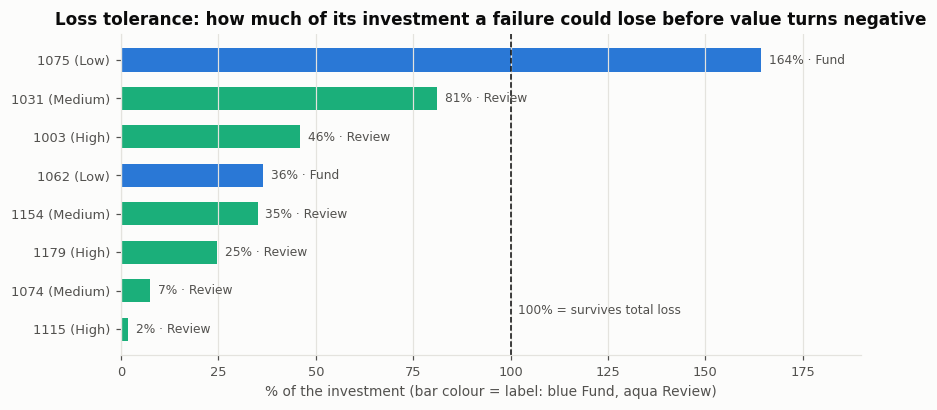

Fund, in order:


,Priority,Initiative_ID,Business_Unit,Risk_Rating,Initial_Investment,NPV_3yr,Expected_NPV,Loss_Tolerance,Funding_Condition
74,1.0,1075,Wealth,Low,220.85,55.57,48.19,1.64,Fund in full
61,2.0,1062,Corporate Banking,Low,103.26,9.86,7.81,0.36,Fund in stages


Review group 1 (positive NPV, higher risk), in order:


,Priority,Initiative_ID,Business_Unit,Risk_Rating,Initial_Investment,NPV_3yr,P_Success,Expected_NPV,Loss_Tolerance
30,1.0,1031,Wealth,Medium,194.04,53.69,0.75,40.05,0.81
2,2.0,1003,Wealth,High,227.64,37.74,0.73,27.72,0.46
153,3.0,1154,Wealth,Medium,162.15,31.34,0.64,20.20,0.35
178,4.0,1179,Digital Banking,High,282.92,28.61,0.71,20.31,0.25
73,5.0,1074,Corporate Banking,Medium,250.17,6.32,0.74,4.71,0.07
114,6.0,1115,SME Lending,High,201.02,1.91,0.65,1.25,0.02


Review group 2 (slow payers), first 10 of 32


,Priority,Initiative_ID,Business_Unit,Risk_Rating,Initial_Investment,NPV_3yr,Break_Even_Years,P_Success
20,1.0,1021,Digital Banking,Low,195.20,-39.28,4.0,0.89
148,2.0,1149,Payments,Low,43.90,-2.30,4.0,0.88
37,3.0,1038,Payments,Low,56.37,-3.89,4.0,0.87
161,4.0,1162,Payments,Low,200.72,-61.32,4.0,0.86
106,5.0,1107,Wealth,Low,140.80,-10.55,4.0,0.86
40,6.0,1041,Digital Banking,Low,62.95,-1.98,4.0,0.85
21,7.0,1022,Payments,Low,67.66,-12.77,4.0,0.85
25,8.0,1026,Payments,Low,242.00,-5.00,4.0,0.85
32,9.0,1033,Risk Analytics,Low,47.56,-3.48,4.0,0.84
176,10.0,1177,SME Lending,Low,216.55,-19.31,4.0,0.83


,Initiatives,Capital_crore,Expected_NPV_lakh,Mean_P,Past_success,Failed_capital_crore,Share_of_capital
Label,,,,,,,
Fund,2,3.241,56.006,0.830,0.500,2.208,0.011
Review,38,62.946,-1006.572,0.812,0.842,9.157,0.222
Reject,140,217.260,-8931.084,0.729,0.750,54.151,0.766


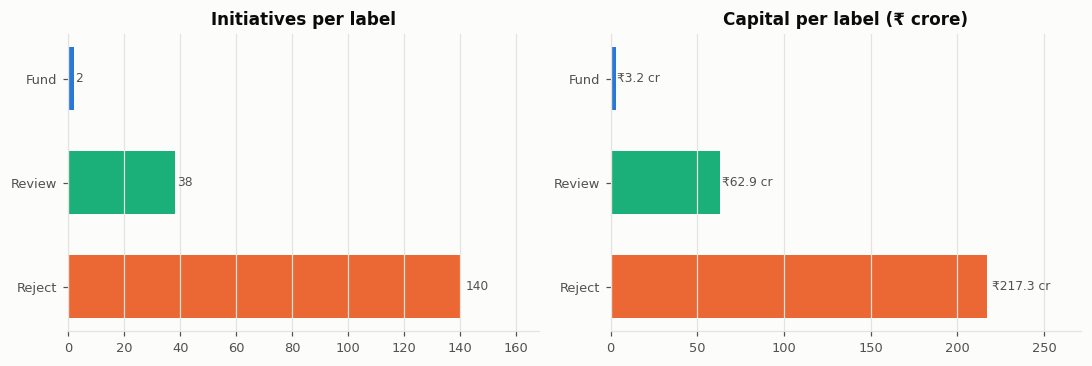

By business unit:


Label,Fund,Review,Reject,Fund (₹ crore),Review (₹ crore),Reject (₹ crore),Total,Reject share
Business_Unit,,,,,,,,
Corporate Banking,1,7,27,1.0,14.8,46.5,35,0.771
Digital Banking,0,7,27,0.0,9.3,37.8,34,0.794
Payments,0,7,29,0.0,10.1,43.2,36,0.806
Risk Analytics,0,7,18,0.0,11.5,28.3,25,0.720
SME Lending,0,2,13,0.0,4.2,18.1,15,0.867
Wealth,1,8,26,2.2,13.1,43.3,35,0.743


By risk level:


Label,Fund,Review,Reject,Fund (₹ crore),Review (₹ crore),Reject (₹ crore),Total,Reject share
Risk_Rating,,,,,,,,
Low,2,25,37,3.2,40.3,55.1,64,0.578
Medium,0,9,63,0.0,15.2,104.3,72,0.875
High,0,4,40,0.0,7.5,57.9,44,0.909


,Fund,Review,Reject,Review capital (₹ crore),Review past success,Decisions different from main
Main: lasso,2.0,38.0,140.0,62.946,0.842,0.0
No model (0.767 for all),2.0,74.0,104.0,117.292,0.757,36.0
Risk rating only,2.0,31.0,147.0,53.477,0.839,7.0


,Alternative run,Main label,Label in this run,Risk_Rating,Initiatives
0,No model (0.767 for all),Reject,Review,High,11
1,No model (0.767 for all),Reject,Review,Medium,25
2,Risk rating only,Review,Reject,High,1
3,Risk rating only,Review,Reject,Medium,6


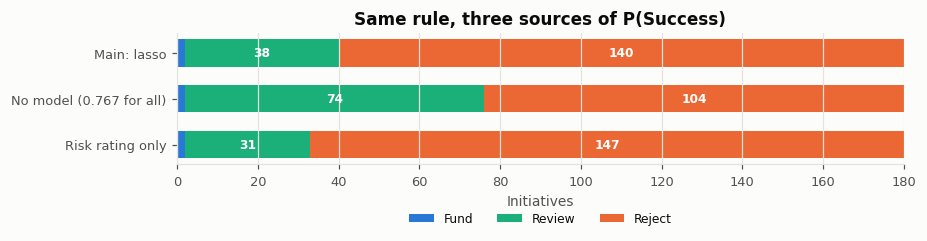

,Years assumed beyond the data,Fund,Review,of which slow payers,Reject,Review capital (₹ crore)
4 years,1.0,2.0,21.0,15.0,157.0,33.0
5 years,2.0,2.0,38.0,32.0,140.0,62.9
6 years,3.0,2.0,47.0,41.0,131.0,77.6


Fund:   2 initiatives, ₹3.2 crore (Expected NPV ₹56.0 lakh)
Review: 38 initiatives, up to ₹62.9 crore if all were approved
Reject: 140 initiatives, ₹217.3 crore not requested further
Share of the Board's ₹1,000 crore: Fund 0.3%; Fund + all Review 6.6%
Why initiatives were rejected:


,Initiatives,Capital_crore
Reason_Code,,
Reject: never pays back,17,24.1
Reject: pays back after the 5-year limit,79,132.1
Reject: fails the hurdle,8,6.7
Reject: flagged at risk by the model,36,54.3


,Initiative_ID,Business_Unit,Risk_Rating,Investment (₹ lakh),NPV 3 years (₹ lakh),P(Success),Expected NPV (₹ lakh),Check: value,Check: risk,Check: payback,Check: hurdle,Check: model,Check: loss tolerance,Decision,Decision path,Funding condition,Priority,Full reason
0,1075,Wealth,Low,220.85,55.57,0.8672,48.19,"Positive: NPV +55.6, Expected NPV +48.2",Low: acceptable for Fund,Year 3: within the 5-year limit,Pass: Expected_ROI 18.9% > cost of money 5.9%,Not at risk: P(Success) 0.87 ≥ 0.767,164%: survives even a total loss,Fund,"Fund: positive value, Low risk",Fund in full,Fund #1 of 2,"Fund in full: positive value (NPV +55.6, Expected NPV +48.2) and Low risk; loss tolerance 164%, survives even a total loss. Other checks: Year 3: within the 5-year limit; Pass: Expected_ROI 18.9% > cost of money 5.9%; Not at risk: P(Success) 0.87 ≥ 0.767."
1,1062,Corporate Banking,Low,103.26,9.86,0.7922,7.81,"Positive: NPV +9.9, Expected NPV +7.8",Low: acceptable for Fund,Year 3: within the 5-year limit,Pass: Expected_ROI 15.4% > cost of money 7.2%,Not at risk: P(Success) 0.79 ≥ 0.767,36%: worth it only if a failure loses at most 36% of the investment,Fund,"Fund: positive value, Low risk",Fund in stages,Fund #2 of 2,"Fund in stages: positive value (NPV +9.9, Expected NPV +7.8) and Low risk; loss tolerance 36%, so money is released in stages. Other checks: Year 3: within the 5-year limit; Pass: Expected_ROI 15.4% > cost of money 7.2%; Not at risk: P(Success) 0.79 ≥ 0.767."
2,1031,Wealth,Medium,194.04,53.69,0.7459,40.05,"Positive: NPV +53.7, Expected NPV +40.0",Medium: not acceptable for Fund without review,Year 3: within the 5-year limit,Pass: Expected_ROI 14.8% > cost of money 5.3%,At risk: P(Success) 0.75 < 0.767,81%: worth it only if a failure loses at most 81% of the investment,Review,Review: positive value but Medium/High risk,Not applicable: decided after review,"Review group 1 (positive value, higher risk): #1 of 6","Review: positive value (NPV +53.7, Expected NPV +40.0) but Medium risk; loss tolerance 81% (how much a failure could lose before it stops being worth it). Other checks: Year 3: within the 5-year limit; Pass: Expected_ROI 14.8% > cost of money 5.3%; At risk: P(Success) 0.75 < 0.767."
3,1003,Wealth,High,227.64,37.74,0.7346,27.72,"Positive: NPV +37.7, Expected NPV +27.7",High: not acceptable for Fund without review,Year 3: within the 5-year limit,Pass: Expected_ROI 15.7% > cost of money 7.4%,At risk: P(Success) 0.73 < 0.767,46%: worth it only if a failure loses at most 46% of the investment,Review,Review: positive value but Medium/High risk,Not applicable: decided after review,"Review group 1 (positive value, higher risk): #2 of 6","Review: positive value (NPV +37.7, Expected NPV +27.7) but High risk; loss tolerance 46% (how much a failure could lose before it stops being worth it). Other checks: Year 3: within the 5-year limit; Pass: Expected_ROI 15.7% > cost of money 7.4%; At risk: P(Success) 0.73 < 0.767."


Example reasons:
- 1075 Fund in full: positive value (NPV +55.6, Expected NPV +48.2) and Low risk; loss tolerance 164%, survives even a total loss. Other checks: Year 3: within the 5-year limit; Pass: Expected_ROI 18.9% > cost of money 5.9%; Not at risk: P(Success) 0.87 ≥ 0.767.
- 1031 Review: positive value (NPV +53.7, Expected NPV +40.0) but Medium risk; loss tolerance 81% (how much a failure could lose before it stops being worth it). Other checks: Year 3: within the 5-year limit; Pass: Expected_ROI 14.8% > cost of money 5.3%; At risk: P(Success) 0.75 < 0.767.
- 1180 Reject: pays back only in year 6 (limit 5). Other checks: Not positive: NPV -32.2, Expected NPV -26.5; Pass: Expected_ROI 8.2% > cost of money 7.7%; Not at risk: P(Success) 0.82 ≥ 0.767; Low: acceptable for Fund.


,Scope,Business unit,Initiatives,Fund now (₹ crore),Capacity (₹ crore),Return if every initiative succeeds (% a year),Expected return (% a year),1-in-20 bad case (% a year),Average P(Success)
0,Fund + Review (deployable),Corporate Banking,8,1.03,15.81,14.32,6.33,-6.13,0.80
1,Fund + Review (deployable),Digital Banking,7,0.00,9.34,22.31,13.20,-6.64,0.81
2,Fund + Review (deployable),Payments,7,0.00,10.08,18.78,13.00,-2.14,0.86
3,Fund + Review (deployable),Risk Analytics,7,0.00,11.50,18.52,10.45,-5.35,0.81
4,Fund + Review (deployable),SME Lending,2,0.00,4.18,25.90,13.34,-1.42,0.74
5,Fund + Review (deployable),Wealth,9,2.21,15.28,27.74,17.59,3.57,0.80
6,Fund + Review (deployable),All units,40,3.24,66.19,20.75,12.13,5.95,0.81
7,All initiatives,Corporate Banking,35,1.03,62.32,5.51,-4.36,-10.10,0.71
8,All initiatives,Digital Banking,34,0.00,47.14,6.11,-1.90,-8.49,0.77
9,All initiatives,Payments,36,0.00,53.33,3.72,-4.39,-10.31,0.75


Deployable initiatives: ₹66.2 crore, expected 12.1% a year (1-in-20 bad case 5.9%). Rejected initiatives would earn less in every unit: Module 1's rejections are confirmed on a return-per-₹ basis.


,Category,Return per ₹ deployed (% a year),Bad-year result per ₹ (% a year),Capacity (₹ crore)
0,Corporate lending (initiatives),6.3,-6.1,15.81
1,Digital banking (initiatives),13.2,-6.6,9.34
2,Digital banking (payments initiatives),13.0,-2.1,10.08
3,Risk management (analytics initiatives),10.4,-5.4,11.50
4,Retail lending (SME initiatives),13.3,-1.4,4.18
5,Wealth management (initiatives),17.6,3.6,15.28


{
  "fund": 2,
  "review": 38,
  "reject": 140,
  "fund_ids": [
    1075,
    1062
  ],
  "fund_conditions": [
    "Fund in full",
    "Fund in stages"
  ],
  "fund_capital_crore": 3.24,
  "review_capital_crore": 62.95,
  "reject_reasons": {
    "Reject: pays back after the 5-year limit": 79,
    "Reject: flagged at risk by the model": 36,
    "Reject: never pays back": 17,
    "Reject: fails the hurdle": 8
  },
  "sensitivity_p_source": {
    "Main: lasso": {
      "fund": 2,
      "review": 38,
      "reject": 140,
      "changed": 0
    },
    "No model (0.767 for all)": {
      "fund": 2,
      "review": 74,
      "reject": 104,
      "changed": 36
    },
    "Risk rating only": {
      "fund": 2,
      "review": 31,
      "reject": 147,
      "changed": 7
    }
  },
  "sensitivity_cutoff_review": {
    "4 years": 21,
    "5 years": 38,
    "6 years": 47
  },
  "module9_by_unit": {
    "Corporate Banking": {
      "capacity_crore": 15.81,
      "expected_return_pct": 6.33,
      "b

In [5]:
%run notebooks/m01_task3_decision.ipynb

## Final output workbook
Builds **`outputs/FINAL_M1_module_output.xlsx`**: the one file to open for this module's results (project decision P-21).
- Tabs: Read me · Key numbers · Board actions · each task's final file · Hand-off to Module 9 · Decisions · Evidence index.
- Every hand-off figure is computed from the task tabs' rows, and each row says which tab, column(s) and rows it comes from.
- Run after all the tasks above.

In [6]:
%run helpers/m01_final_output.py

Saved: FINAL_M1_module_output.xlsx
                                                Figure                                                                                                                                                      Value                      Unit
                                     Ready to fund now                                                                                                                                                       3.24                   ₹ crore
                           The initiatives to fund now                                                                                                                 1075 (Fund in full); 1062 (Fund in stages)                         —
                   Possible after review (upper bound)                                                                                                                                                      62.95                   ₹ crore
                     